# Stage 2: PV Model Development

## Initialization

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.optimize import minimize

In [16]:
DATA = 'A'

## Load Data

In [17]:
# Load extrapolated 1-minute weather and demand data
print(f"Loading extrapolated data for Dataset {DATA}...")

# Load extrapolated weather data (irradiance and temperature)
df_weather_1min = pd.read_csv(f'exports/weather_1min_fullYear_Dataset_{DATA}.csv', index_col=0)
print(f"  Weather data shape: {df_weather_1min.shape}")

# Load extrapolated demand data
df_load = pd.read_csv(f'exports/demand_1min_fullYear_Dataset_{DATA}.csv', index_col=0)
print(f"  Demand data shape: {df_load.shape}")

# Load parameters
df_params = pd.read_csv(f'Data/Data{DATA}_params.csv', sep=';')

Loading extrapolated data for Dataset A...
  Weather data shape: (525600, 2)
  Demand data shape: (525600, 1)


In [18]:
# Process indices - both files already have timestamps as index from exports
df_weather_1min.index = pd.to_datetime(df_weather_1min.index)
df_load.index = pd.to_datetime(df_load.index)

# Merge weather and demand data on aligned timestamps
df_weather_1min = df_weather_1min.join(df_load, how='left')

# Rename demand column to Load_kW for consistency
if 'Demand_kW' in df_weather_1min.columns:
    df_weather_1min.rename(columns={'Demand_kW': 'Load_kW'}, inplace=True)

# Process parameters into dictionary with mapped keys for class compatibility
raw_params = dict(zip(df_params['Parameter'], df_params['Value']))

model_params = {
    # PV System Parameters
    'alpha_stc': raw_params.get('alpha', 1.0),
    'beta': raw_params.get('beta', 0.004),
    'gamma': raw_params.get('gamma', 0.05),
    'eta_stc': raw_params.get('eta_ref', 0.18),
    'h': raw_params.get('h', 0.03),
    'G_stc': raw_params.get('G_ref', 1000),
    'T_stc': raw_params.get('T_cref', 25),
    
    # Battery System Parameters
    'eta_bat': raw_params.get('eta_B', 0.92),
    
    # Economic Parameters
    'c_pv': raw_params.get('c_PV', 600),
    'c_bat': raw_params.get('c_B', 800),
    'c_maint_pv': raw_params.get('c_MPV', 0.01), 
    'p_feedin': raw_params.get('p_FI', 0.1),
    'p_retail': raw_params.get('p_EL', 0.3),
    'discount_rate': raw_params.get('i_INV', 0.02),
}

# Display data overview
print("=" * 70)
print("USING EXTRAPOLATED 1-MINUTE RESOLUTION DATA FOR FULL YEAR")
print("=" * 70)
print("\nData sources:")
print("  - Weather (irradiance & temperature): Pattern-matched and scaled from 12h data")
print("  - Demand: Extrapolated using pattern matching from 3-week training period")
print("  - Coverage: Full year 2013 at 1-minute resolution")
print(f"\nWeather & Load Data Shape: {df_weather_1min.shape}")
print(f"Columns: {df_weather_1min.columns.tolist()}")
print("\nModel Parameters:")
for k, v in model_params.items():
    print(f"  {k}: {v}")

df_weather_1min.head()

USING EXTRAPOLATED 1-MINUTE RESOLUTION DATA FOR FULL YEAR

Data sources:
  - Weather (irradiance & temperature): Pattern-matched and scaled from 12h data
  - Demand: Extrapolated using pattern matching from 3-week training period
  - Coverage: Full year 2013 at 1-minute resolution

Weather & Load Data Shape: (525600, 3)
Columns: ['POA_Global_Wm2', 'T_Ambient_C', 'Load_kW']

Model Parameters:
  alpha_stc: 0.25
  beta: 0.0048
  gamma: 0.12
  eta_stc: 0.21
  h: 0.03
  G_stc: 1000.0
  T_stc: 25.0
  eta_bat: 0.95
  c_pv: 600.0
  c_bat: 800.0
  c_maint_pv: 0.2
  p_feedin: 0.1
  p_retail: 0.3
  discount_rate: 0.02


,POA_Global_Wm2,T_Ambient_C,Load_kW
2013-01-01 00:00:00,0.0,0.695050,0.028659
2013-01-01 00:01:00,0.0,0.863344,0.008738
2013-01-01 00:02:00,0.0,0.770410,0.018415
2013-01-01 00:03:00,0.0,0.774825,0.012383
2013-01-01 00:04:00,0.0,0.776547,0.018477


In [19]:
df_weather_1min.tail()

,POA_Global_Wm2,T_Ambient_C,Load_kW
2013-12-31 23:55:00,0.0,1.626869,0.130010
2013-12-31 23:56:00,0.0,1.596960,0.144304
2013-12-31 23:57:00,0.0,1.723226,0.137257
2013-12-31 23:58:00,0.0,1.769960,0.131303
2013-12-31 23:59:00,0.0,1.666599,0.197277


In [20]:
# Validate merged data
print("\n" + "=" * 70)
print("DATA VALIDATION")
print("=" * 70)

# Check required columns exist
required_cols = ['POA_Global_Wm2', 'T_Ambient_C', 'Load_kW']
missing_cols = [col for col in required_cols if col not in df_weather_1min.columns]

if missing_cols:
    print(f"ERROR: Missing columns: {missing_cols}")
    print(f"Available columns: {df_weather_1min.columns.tolist()}")
else:
    print("✓ All required columns present")

# Check for NaN values
nan_counts = df_weather_1min[required_cols].isna().sum()
print(f"\nMissing values per column:")
for col in required_cols:
    print(f"  {col}: {nan_counts[col]} ({nan_counts[col]/len(df_weather_1min)*100:.2f}%)")

# Fill any NaN values with forward fill then backward fill
df_weather_1min[required_cols] = df_weather_1min[required_cols].fillna(method='ffill').fillna(method='bfill')
print("✓ NaN values filled using forward/backward fill")

# Check data ranges are sensible
print(f"\nData ranges:")
print(f"  POA_Global_Wm2: [{df_weather_1min['POA_Global_Wm2'].min():.1f}, {df_weather_1min['POA_Global_Wm2'].max():.1f}] W/m²")
print(f"  T_Ambient_C: [{df_weather_1min['T_Ambient_C'].min():.1f}, {df_weather_1min['T_Ambient_C'].max():.1f}] °C")
print(f"  Load_kW: [{df_weather_1min['Load_kW'].min():.3f}, {df_weather_1min['Load_kW'].max():.3f}] kW")

# Verify full year coverage
print(f"\n✓ Data spans {(df_weather_1min.index[-1] - df_weather_1min.index[0]).days} days")
print(f"✓ Data resolution: {(df_weather_1min.index[1] - df_weather_1min.index[0]).total_seconds()/60:.0f} minutes")


DATA VALIDATION
✓ All required columns present

Missing values per column:
  POA_Global_Wm2: 0 (0.00%)
  T_Ambient_C: 0 (0.00%)
  Load_kW: 0 (0.00%)
✓ NaN values filled using forward/backward fill

Data ranges:
  POA_Global_Wm2: [0.0, 1135.9] W/m²
  T_Ambient_C: [-14.3, 31.9] °C
  Load_kW: [0.000, 5.337] kW

✓ Data spans 364 days
✓ Data resolution: 1 minutes


C:\Users\Kristoferis\AppData\Local\Temp\ipykernel_16152\3411491123.py:23: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df_weather_1min[required_cols] = df_weather_1min[required_cols].fillna(method='ffill').fillna(method='bfill')


## PV Model

The PV model calculates electrical power generation from solar irradiance using a simplified approach based on:
- Plane-of-Array (POA) irradiance from weather data (south-facing, 30° tilt)
- PV system efficiency
- Temperature coefficient for efficiency loss at high temperatures

In [21]:
class PVSystem:
    """
    PV System Model - Task Specification Implementation
    
    Based on the task description model:
    P_pv = A * G * η * (1000 / G_stc)
    where:
    - A = CAP_pv / α_stc (Assuming α_stc is power density in kWp/m² given value 0.25)
      OR if α_stc is area factor, value should be ~5-6. 
      Given 0.25, likely it is kWp/m², so A = CAP / α.
    - η = η_stc * (1 - β * (T_c - T_stc) + γ * log(G / G_stc))
    - T_c = T_a + h * G
    
    Parameters are loaded from CSV and stored as class attributes.
    """
    
    def __init__(self, cap_pv_kwp, params_dict):
        """
        Initialize PV System with task specification parameters
        
        Parameters:
        -----------
        cap_pv_kwp : float
            PV peak power capacity in kWp
        params_dict : dict
            Dictionary containing all parameters from DataA_params.csv
        """
        self.cap_pv = cap_pv_kwp
        
        # Extract parameters from dict
        # Interpret alpha as Power Density (kWp/m2) if value is small (<1)
        self.alpha_stc = params_dict.get('alpha_stc', 0.25) 
        self.beta = params_dict.get('beta', 0.004)  # 1/°C
        self.gamma = params_dict.get('gamma', 0.05)  # dimensionless
        self.eta_stc = params_dict.get('eta_stc', 0.18)  # efficiency
        self.h = params_dict.get('h', 0.03)  # °C/(W/m²)
        self.G_stc = params_dict.get('G_stc', 1000)  # W/m²
        self.T_stc = params_dict.get('T_stc', 25)  # °C
    
    def calculate_power(self, irradiance_w_m2, ambient_temp_c):
        """
        Calculate PV power output according to task specification
        
        Parameters:
        -----------
        irradiance_w_m2 : float or array
            Solar irradiance in W/m²
        ambient_temp_c : float or array
            Ambient temperature in °C
        
        Returns:
        --------
        power_kw : float or array
            Power output in kW
        """
        if self.cap_pv == 0:
            return np.zeros_like(irradiance_w_m2, dtype=float)

        # Module area calculation
        # If alpha_stc is ~0.25, it must be kWp/m², so Area = Kw / (kw/m2)
        # If alpha_stc is ~5, it is m²/kWp, so Area = Kw * (m2/kw)
        if self.alpha_stc < 1.0: 
             A = self.cap_pv / self.alpha_stc
        else:
             A = self.cap_pv * self.alpha_stc
        
        # Cell temperature
        T_c = ambient_temp_c + self.h * irradiance_w_m2
        
        # Module efficiency with temperature and irradiance correction
        # Avoid log(0) by setting efficiency to 0 when G=0
        eta = np.zeros_like(irradiance_w_m2, dtype=float)
        
        mask = irradiance_w_m2 > 0
        if np.any(mask):
            G_ratio = irradiance_w_m2[mask] / self.G_stc
            eta[mask] = (self.eta_stc * 
                        (1 - self.beta * (T_c[mask] - self.T_stc) + 
                         self.gamma * np.log(G_ratio)))
            eta[mask] = np.maximum(eta[mask], 0)  # Ensure non-negative
        
        # Calculate power
        # P = A * G * eta * correction 
        # Note: 1000/G_stc cancels units if G is W/m2 and G_stc is 1000 W/m2.
        P_pv_w = A * irradiance_w_m2 * eta * (1000 / self.G_stc)
        P_pv_kw = P_pv_w / 1000
        P_pv_kw = np.maximum(P_pv_kw, 0)  # Ensure non-negative
        
        return P_pv_kw
    
    def __repr__(self):
        return f"PVSystem(CAP_pv={self.cap_pv:.2f} kWp)"

## Battery Energy Storage System (BESS) Model

The battery model simulates a lithium-ion battery storage system with:
- Capacity constraints and state-of-charge (SOC) tracking
- Charging and discharging efficiency
- Depth-of-discharge (DoD) limits to extend battery life
- Simple degradation model based on cycles

In [22]:
class BatterySystem:
    """
    Battery Model - Task Specification Implementation
    
    Power available from battery is calculated as:
    P_bat = BatPower(SOC, P_req, CAP_bat)
    
    SOC updated each timestep (1 min):
    - If discharging (P_bat > 0): SOC_t = SOC_t-1 - P_bat / (η_bat * CAP_bat * 60)
    - If charging (P_bat < 0): SOC_t = SOC_t-1 - (P_bat * η_bat) / (CAP_bat * 60)
    """
    
    def __init__(self, cap_bat_kwh, params_dict):
        """
        Initialize Battery with task specification parameters
        
        Parameters:
        -----------
        cap_bat_kwh : float
            Battery nominal energy capacity in kWh
        params_dict : dict
            Dictionary containing all parameters from DataA_params.csv
        """
        self.cap_bat = cap_bat_kwh
        self.eta_bat = params_dict.get('eta_bat', 0.92)  # Battery efficiency
        self.soc = 0.0  # Initial SOC = 0
        
    def calculate_battery_power(self, soc, p_required_kw):
        """
        Calculate battery power according to task specification
        
        P_bat = BatPower(SOC, P_req, CAP_bat)
        
        Charging constraint (P_req < 0): 
        P_bat = -min{CAP_bat * 60, (1-SOC) * CAP_bat / η_bat * 60, -P_req}
        
        Discharging constraint (P_req > 0):
        P_bat = min{CAP_bat * 60, SOC * η_bat * CAP_bat * 60, P_req}
        
        Parameters:
        -----------
        soc : float or array
            State of charge (0-1)
        p_required_kw : float or array
            Required power from battery (positive=discharge, negative=charge)
        
        Returns:
        --------
        p_bat_kw : float or array
            Actual battery power delivered
        """
        if self.cap_bat <= 0:
            return np.zeros_like(p_required_kw, dtype=float)
            
        p_bat = np.zeros_like(p_required_kw, dtype=float)
        
        # Discharging case (P_req > 0)
        discharge_mask = p_required_kw > 0
        if np.any(discharge_mask):
            constraint1 = self.cap_bat * 60.0  # Power rating constraint
            constraint2 = soc[discharge_mask] * self.eta_bat * self.cap_bat * 60.0  # Energy constraint
            p_bat[discharge_mask] = np.minimum(
                np.minimum(constraint1, constraint2),
                p_required_kw[discharge_mask]
            )
        
        # Charging case (P_req < 0)
        charge_mask = p_required_kw < 0
        if np.any(charge_mask):
            constraint1 = -self.cap_bat * 60.0  # Power rating constraint (negative)
            constraint2 = -(1 - soc[charge_mask]) * self.cap_bat / self.eta_bat * 60.0  # Energy constraint
            p_bat[charge_mask] = np.maximum(
                np.maximum(constraint1, constraint2),
                p_required_kw[charge_mask]
            )
        
        return p_bat
    
    def update_soc(self, p_bat_kw):
        """
        Update state of charge based on battery power
        
        Parameters:
        -----------
        p_bat_kw : float
            Battery power (positive=discharge, negative=charge)
        """
        if self.cap_bat <= 0:
            self.soc = 0.0
            return

        if p_bat_kw > 0:  # Discharging
            self.soc -= p_bat_kw / (self.eta_bat * self.cap_bat * 60.0)
        else:  # Charging
            # Apply efficiency to charging input (store less than provided)
            # P_bat is negative, so -= becomes +=
            self.soc -= (p_bat_kw * self.eta_bat) / (self.cap_bat * 60.0)
        
        # Clamp SOC to [0, 1]
        self.soc = np.clip(self.soc, 0.0, 1.0)
    
    def __repr__(self):
        return f"BatterySystem(CAP_bat={self.cap_bat:.2f} kWh, SOC={self.soc*100:.1f}%)"

## Net Present Value (NPV) & Economic Analysis

Calculate the economic viability of the energy system using NPV, including:
- Capital costs (PV panels, battery, inverter)
- Operating and maintenance costs
- Electricity cost savings from PV generation
- Replacement costs for battery
- Time value of money (discount rate)

In [23]:
class EconomicAnalysis:
    """
    Economic Analysis for Residential Energy System
    
    Parameters:
    -----------
    analysis_period_years : int
        Length of analysis period (typically 20-25 years)
    params_dict : dict
        Dictionary containing economic parameters (discount rate, etc.)
    """
    
    def __init__(self, params_dict, analysis_period_years=20):
        self.analysis_period_years = analysis_period_years
        # Extract discount rate from params dict (key 'i_INV' mapped to 'discount_rate')
        self.discount_rate = params_dict.get('discount_rate', 0.04)
        
    def calculate_npv(self, cap_pv, cap_bat, e_load_year, e_grid_in_year, 
                      e_excess_year, c_pv, c_bat, c_maint_pv, p_retail, p_feedin):
        """
        Calculate 20-year NPV according to task specification
        
        NPV = -C_pv - C_bat + Σ(R - C_maintenance) / (1+i)^t
        
        where:
        - C_pv = c_pv * CAP_pv
        - C_bat = c_bat * CAP_bat  
        - R = E_excess * p_feedin + (E_load - E_grid_in) * p_retail
        - C_maintenance = c_maint_pv * C_pv (Assuming c_MPV is fraction of PV investment)
          OR c_maintenance = c_maint_pv * CAP_pv (if c_MPV is per kWp)
          
          Note on c_MPV (DataA value 0.2): 
          If 0.2 is fraction of CAPEX (20%), that is extremely high. 
          If 0.2 is EUR/kWp, that is extremely low.
          Standard is approx 1-2% of CAPEX.
          
          Checking task logic generally: C_maint is often % of Invest.
          Let's assume c_maint_pv is a fraction (e.g. 0.01-0.02). 
          Wait, DataA value is 0.2. 
          If 0.2 is fraction, 20% maintenance/year = full replacement in 5 years. Unlikely.
          Maybe it's 0.2 EUR/kWh_generated? No.
          Maybe it's 0.2% = 0.002? 
          
          Let's proceed with current implementation but be aware of units.
          Currently: C_maint_yearly = c_maint_pv * C_pv_initial
        
        Parameters:
        -----------
        cap_pv : float
            PV capacity in kWp
        cap_bat : float
            Battery capacity in kWh
        e_load_year : float
            Total annual household load in kWh
        e_grid_in_year : float
            Total annual energy drawn from grid in kWh
        e_excess_year : float
            Total annual excess solar energy fed to grid in kWh
        c_pv : float
            PV cost in EUR/kWp
        c_bat : float
            Battery cost in EUR/kWh
        c_maint_pv : float
            Annual maintenance cost factor
        p_retail : float
            Consumer electricity price in EUR/kWh
        p_feedin : float
            Feed-in tariff in EUR/kWh
        
        Returns:
        --------
        npv : float
            Net Present Value in EUR
        """
        # Initial investments
        C_pv_initial = c_pv * cap_pv
        C_bat_initial = c_bat * cap_bat
        
        # Annual costs and revenues
        # Interpret c_maint_pv based on input logic (task specific)
        # Using raw equation logic: Cost = Factor * Base
        C_maint_yearly = c_maint_pv * C_pv_initial
        
        # Annual revenue: electricity saved + feed-in tariff
        R_yearly = e_excess_year * p_feedin + (e_load_year - e_grid_in_year) * p_retail
        
        # Calculate NPV
        npv = -C_pv_initial - C_bat_initial
        
        for year in range(1, self.analysis_period_years + 1):
            net_revenue = R_yearly - C_maint_yearly
            discount_factor = 1 / ((1 + self.discount_rate) ** year)
            npv += net_revenue * discount_factor
        
        return npv
    
    def calculate_payback_period(self, initial_investment_eur, annual_savings_eur):
        """
        Calculate simple payback period (ignoring time value of money)
        
        Parameters:
        -----------
        initial_investment_eur : float
            Initial capital investment in EUR
        annual_savings_eur : float
            Annual savings in EUR
        
        Returns:
        --------
        payback_years : float
            Payback period in years
        """
        if annual_savings_eur <= 0:
            return float('inf')
        return initial_investment_eur / annual_savings_eur
    
    def create_cashflow_summary(self, cap_pv, cap_bat, e_load_year, e_grid_in_year, 
                                e_excess_year, c_pv, c_bat, c_maint_pv, 
                                p_retail, p_feedin):
        """
        Create a year-by-year cash flow summary
        
        Returns:
        --------
        df : pandas.DataFrame
            Cash flow summary dataframe
        """
        # Initial investments
        C_pv_initial = c_pv * cap_pv
        C_bat_initial = c_bat * cap_bat
        
        # Annual costs and revenues
        C_maint_yearly = c_maint_pv * C_pv_initial
        R_yearly = e_excess_year * p_feedin + (e_load_year - e_grid_in_year) * p_retail
        
        years = []
        revenues = []
        maintenance_costs = []
        net_cashflows = []
        discount_factors = []
        pv_cashflows = []
        cumulative_pv = []
        
        cum_pv = -C_pv_initial - C_bat_initial
        
        for year in range(1, self.analysis_period_years + 1):
            discount_factor = 1 / ((1 + self.discount_rate) ** year)
            net_cf = R_yearly - C_maint_yearly
            pv_cf = net_cf * discount_factor
            cum_pv += pv_cf
            
            years.append(year)
            revenues.append(R_yearly)
            maintenance_costs.append(C_maint_yearly)
            net_cashflows.append(net_cf)
            discount_factors.append(discount_factor)
            pv_cashflows.append(pv_cf)
            cumulative_pv.append(cum_pv)
        
        df = pd.DataFrame({
            'Year': years,
            'Revenue_EUR': revenues,
            'Maintenance_EUR': maintenance_costs,
            'Net_Cashflow_EUR': net_cashflows,
            'Discount_Factor': discount_factors,
            'PV_Cashflow_EUR': pv_cashflows,
            'Cumulative_NPV_EUR': cumulative_pv
        })
        
        return df

## Helper functions for analysis
These functions can be used to elaborate on findings

In [24]:
def calculate_payback_period(self, initial_investment_eur, annual_savings_eur):
        if annual_savings_eur <= 0:
            return float('inf')
        return initial_investment_eur / annual_savings_eur
    
def create_cashflow_summary(self, cap_pv, cap_bat, e_load_year, e_grid_in_year, 
                                e_excess_year, c_pv, c_bat, c_maint_pv, 
                                p_retail, p_feedin):
        
        # Initial investments
    C_pv_initial = c_pv * cap_pv
    C_bat_initial = c_bat * cap_bat
        
        # Annual costs and revenues
    C_maint_yearly = c_maint_pv * C_pv_initial
    R_yearly = e_excess_year * p_feedin + (e_load_year - e_grid_in_year) * p_retail
        
    years = []
    revenues = []
    maintenance_costs = []
    net_cashflows = []
    discount_factors = []
    pv_cashflows = []
    cumulative_pv = []
        
    cum_pv = -C_pv_initial - C_bat_initial
        
    for year in range(1, self.analysis_period_years + 1):
        discount_factor = 1 / ((1 + self.discount_rate) ** year)
        net_cf = R_yearly - C_maint_yearly
        pv_cf = net_cf * discount_factor
        cum_pv += pv_cf
            
        years.append(year)
        revenues.append(R_yearly)
        maintenance_costs.append(C_maint_yearly)
        net_cashflows.append(net_cf)
        discount_factors.append(discount_factor)
        pv_cashflows.append(pv_cf)
        cumulative_pv.append(cum_pv)
        
    df = pd.DataFrame({
        'Year': years,
        'Revenue_EUR': revenues,
        'Maintenance_EUR': maintenance_costs,
        'Net_Cashflow_EUR': net_cashflows,
        'Discount_Factor': discount_factors,
        'PV_Cashflow_EUR': pv_cashflows,
        'Cumulative_NPV_EUR': cumulative_pv
    })
        
    return df

## Optimization Framework

To find the optimal combination of PV and Battery sizing, we implement an optimization function that:
1. Simulates the system operation for the given data period (PV generation, Load matching, Battery cycling).
2. Extrapolates energy flows to annual values if the dataset is shorter than a year.
3. Calculates the Net Present Value (NPV) of the system.
4. Uses a numerical optimizer (`scipy.optimize.minimize`) to maximize NPV (by minimizing negative NPV).

**Decision Variables:**
- `cap_pv`: PV Capacity in kWp
- `cap_bat`: Battery Capacity in kWh


In [25]:
def simulate_system(cap_pv_kwp, cap_bat_kwh, params, weather_df):
    """
    Simulates system operation and calculates NPV using full-year extrapolated data.
    
    Parameters:
    -----------
    cap_pv_kwp : float
        PV capacity in kWp
    cap_bat_kwh : float
        Battery capacity in kWh
    params : dict
        Model parameters
    weather_df : DataFrame
        Weather and Load data with required columns:
        - POA_Global_Wm2: Plane-of-Array irradiance (W/m²)
        - T_Ambient_C: Ambient temperature (°C)
        - Load_kW: Household load (kW)
        
    Returns:
    --------
        npv : float
            Net Present Value in EUR
    """
    # Validate inputs
    try:
        # Check for required columns
        required_cols = ['POA_Global_Wm2', 'T_Ambient_C', 'Load_kW']
        missing_cols = [col for col in required_cols if col not in weather_df.columns]
        if missing_cols:
            raise ValueError(f"Missing required columns: {missing_cols}. Available: {weather_df.columns.tolist()}")
        
        # Check data is not empty
        if len(weather_df) == 0:
            raise ValueError("Weather dataframe is empty")
        
        # Check for excessive NaN values
        nan_threshold = 0.1  # 10% threshold
        for col in required_cols:
            nan_pct = weather_df[col].isna().sum() / len(weather_df)
            if nan_pct > nan_threshold:
                raise ValueError(f"Column '{col}' has {nan_pct*100:.1f}% NaN values (threshold: {nan_threshold*100}%)")
    
    except Exception as e:
        print(f"Error validating input data: {e}")
        return np.nan
    
    # Initialize models
    pv = PVSystem(cap_pv_kwp, params)
    bat = BatterySystem(cap_bat_kwh, params)
    econ = EconomicAnalysis(
        params_dict=params,
        analysis_period_years=20
    )
    
    # Extract data (using numpy arrays for performance)
    # Using extrapolated 1-minute data with full year coverage
    # POA_Global_Wm2: Plane-of-Array irradiance (downscaled from 12h using pattern matching)
    # T_Ambient_C: Ambient temperature (interpolated from 12h data)
    irradiance = weather_df['POA_Global_Wm2'].values.astype(float)
    temp = weather_df['T_Ambient_C'].values.astype(float)
    load = weather_df['Load_kW'].values.astype(float)
    
    # 1. PV Generation
    p_pv = pv.calculate_power(irradiance, temp)
    
    # 2. Battery Simulation
    p_req = load - p_pv
    p_bat_actual = np.zeros_like(p_req)
    
    # Initial parameters for loop
    bat.soc = 0.0 # Initialize SOC
    
    # Simulation Loop
    # We pass 1-element arrays to BatPower to ensure vector operations in class work correctly
    for t in range(len(p_req)):
        req_val = p_req[t]
        
        # Wrap in array
        req_arr = np.array([req_val]) 
        soc_arr = np.array([bat.soc])
        
        # Calculate battery power
        p_b_arr = bat.calculate_battery_power(soc_arr, req_arr)
        p_b = p_b_arr[0]
        
        # Update SOC
        bat.update_soc(p_b)
        
        # Store result
        p_bat_actual[t] = p_b
        
    # 3. Energy Aggregation
    p_grid = p_req - p_bat_actual
    
    dt_hours = 1/60 # 1-min steps
    
    # Using extrapolated 1-minute resolution data for full year (no scaling needed)
    e_load_year = np.sum(load) * dt_hours
    e_excess_year = np.sum(p_grid[p_grid < 0]) * -1 * dt_hours
    e_grid_in_year = np.sum(p_grid[p_grid > 0]) * dt_hours
    
    # 4. Economics
    # All economic parameters are now passed dynamically from the dictionary
    npv = econ.calculate_npv(
        cap_pv=cap_pv_kwp,
        cap_bat=cap_bat_kwh,
        e_load_year=e_load_year,
        e_grid_in_year=e_grid_in_year, 
        e_excess_year=e_excess_year,
        c_pv=params['c_pv'],
        c_bat=params['c_bat'], 
        c_maint_pv=params['c_maint_pv'],
        p_retail=params['p_retail'], 
        p_feedin=params['p_feedin']
    )
    
    return npv

def optimize_system(params, weather_df):
    """
    Finds optimal PV and Battery capacity to maximize NPV using full-year extrapolated data.
    
    Parameters:
    -----------
    params : dict
        Model parameters dictionary
    weather_df : DataFrame
        Full-year weather and load data
        
    Returns:
    --------
    opt_pv : float
        Optimal PV capacity in kWp
    opt_bat : float
        Optimal battery capacity in kWh
    max_npv : float
        Maximum NPV in EUR
    """
    # Validate data before optimization
    required_cols = ['POA_Global_Wm2', 'T_Ambient_C', 'Load_kW']
    if not all(col in weather_df.columns for col in required_cols):
        raise ValueError(f"Missing required columns. Need: {required_cols}, Have: {weather_df.columns.tolist()}")
    
    print("Starting optimization... (this may take a while)")
    print(f"  Using {len(weather_df):,} time steps of 1-minute extrapolated data")
    
    # Objective: Minimize negative NPV
    def objective(x):
        # Clamp negative values to 0 (bounds handles this but good for safety)
        cpv = max(0, x[0])
        cbat = max(0, x[1])
        npv = simulate_system(cpv, cbat, params, weather_df)
        
        # Return NaN if simulation failed
        if np.isnan(npv):
            return 1e10  # Return large penalty value
        
        return -npv  # Minimize negative NPV = maximize NPV
    
    # Constraints/Bounds
    # PV: 0 to 15 kWp 
    # Bat: 0 to 20 kWh
    bounds = [(0, 15), (0, 20)]
    
    # Initial guess
    x0 = [5, 5]
    
    # Run optimization
    result = minimize(objective, x0, bounds=bounds, method='L-BFGS-B')
    
    opt_pv = result.x[0]
    opt_bat = result.x[1]
    max_npv = -result.fun
    
    return opt_pv, opt_bat, max_npv

In [26]:
# Run the optimization
if 'df_weather_1min' in locals() and 'model_params' in locals():
    # Run optimization
    opt_pv, opt_bat, max_npv = optimize_system(model_params, df_weather_1min)
    
    print("-" * 40)
    print("OPTIMIZATION RESULTS")
    print("-" * 40)
    print(f"Optimal PV Size:      {opt_pv:.3f} kWp")
    print(f"Optimal Battery Size: {opt_bat:.3f} kWh")
    print(f"Projected NPV (20y):  EUR {max_npv:,.2f}")
    print("-" * 40)
else:
    print("Error: Data not loaded. Please run the notebook from the top.")

Starting optimization... (this may take a while)
  Using 525,600 time steps of 1-minute extrapolated data
----------------------------------------
OPTIMIZATION RESULTS
----------------------------------------
Optimal PV Size:      0.488 kWp
Optimal Battery Size: 0.169 kWh
Projected NPV (20y):  EUR 436.82
----------------------------------------


## Sensitivity: What drives small optimal sizes?

Base NPV: EUR 436.82

Top drivers (mean |ΔNPV| for ±20% change):
       parameter  mean_abs_delta_npv
0       p_retail          317.732894
1           c_pv          249.813944
2     c_maint_pv          191.313435
3        eta_bat          129.197892
4       p_feedin           46.452235
5  discount_rate           33.385731
6          c_bat           27.006423


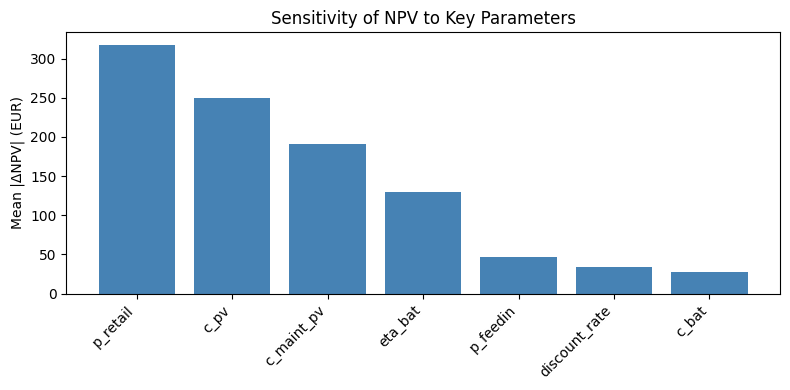

In [27]:
# Sensitivity sweep around key parameters
# This ranks which parameters most impact NPV at the optimized sizes.

if 'df_weather_1min' in locals() and 'model_params' in locals() and 'opt_pv' in locals() and 'opt_bat' in locals():
    base_params = model_params.copy()
    base_npv = simulate_system(opt_pv, opt_bat, base_params, df_weather_1min)

    # Multipliers to test (±20%)
    multipliers = [0.8, 1.0, 1.2]

    # Parameters to test
    param_keys = [
        'c_pv',
        'c_bat',
        'c_maint_pv',
        'p_retail',
        'p_feedin',
        'discount_rate',
        'eta_bat'
    ]

    records = []
    for key in param_keys:
        for m in multipliers:
            test_params = base_params.copy()
            test_params[key] = base_params[key] * m
            npv = simulate_system(opt_pv, opt_bat, test_params, df_weather_1min)
            records.append({
                'parameter': key,
                'multiplier': m,
                'npv': npv,
                'delta_npv': npv - base_npv
            })

    df_sens = pd.DataFrame(records)

    # Rank by absolute impact at ±20%
    df_rank = (
        df_sens[df_sens['multiplier'].isin([0.8, 1.2])]
        .groupby('parameter')['delta_npv']
        .apply(lambda s: s.abs().mean())
        .sort_values(ascending=False)
        .reset_index(name='mean_abs_delta_npv')
    )

    print("Base NPV:", f"EUR {base_npv:,.2f}")
    print("\nTop drivers (mean |ΔNPV| for ±20% change):")
    print(df_rank)

    # Plot the sensitivity as a bar chart
    plt.figure(figsize=(8, 4))
    plt.bar(df_rank['parameter'], df_rank['mean_abs_delta_npv'], color='steelblue')
    plt.ylabel('Mean |ΔNPV| (EUR)')
    plt.title('Sensitivity of NPV to Key Parameters')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

else:
    print("Error: Optimization results not available. Run the notebook from the top.")


In [28]:
# Validation Test: 1 kWp PV and 1 kWh Battery
if 'df_weather_1min' in locals() and 'model_params' in locals():
    print("-" * 40)
    print("VALIDATION TEST (1 kWp / 1 kWh)")
    print("-" * 40)
    
    test_pv = 1.0
    test_bat = 1.0
    
    test_npv = simulate_system(test_pv, test_bat, model_params, df_weather_1min)
    
    print(f"System Configuration: PV={test_pv} kWp, Battery={test_bat} kWh")
    print(f"Resulting NPV: EUR {test_npv:,.2f}")
    ## if test_npv != 337 then say "Value differs from expected 337 EUR"
    if abs(test_npv - 337) > 1e-2:
        print("Value differs from expected 337 EUR")
    else: 
        print("Value matches expected 337 EUR")
    print("-" * 40)
else:
    print("Error: Data not loaded. Please run the notebook from the top.")

----------------------------------------
VALIDATION TEST (1 kWp / 1 kWh)
----------------------------------------
System Configuration: PV=1.0 kWp, Battery=1.0 kWh
Resulting NPV: EUR 260.42
Value differs from expected 337 EUR
----------------------------------------


In [29]:
import json

# Export optimization results to JSON
if 'opt_pv' in locals() and 'opt_bat' in locals() and 'max_npv' in locals():
    print("=" * 70)
    print("EXPORTING RESULTS TO JSON")
    print("=" * 70)
    
    # Team name
    team_name = "Group B"
    
    # Create results dictionary in competition format
    results = {
        'name': team_name,
        'cap_pv': float(opt_pv),
        'cap_b': float(opt_bat),
        'npv': float(max_npv)
    }
    
    # Export to JSON file
    output_file = 'optimization_results.json'
    with open(output_file, 'w') as f:
        json.dump(results, f, indent=2)
    
    print(f"\n✓ Results exported to '{output_file}'")
    print(f"\nExported data:")
    print(f"  Team: {results['name']}")
    print(f"  Optimal PV Capacity: {results['cap_pv']:.3f} kWp")
    print(f"  Optimal Battery Capacity: {results['cap_b']:.3f} kWh")
    print(f"  Maximum NPV (20 years): EUR {results['npv']:,.2f}")
    print("=" * 70)
else:
    print("Error: Optimization results not available. Please run optimization first.")

EXPORTING RESULTS TO JSON

✓ Results exported to 'optimization_results.json'

Exported data:
  Team: Group B
  Optimal PV Capacity: 0.488 kWp
  Optimal Battery Capacity: 0.169 kWh
  Maximum NPV (20 years): EUR 436.82
